# Makine Öğrenmesi — 4. Ünite: Parametrik Yöntemler
## 120 dakikalık canlı ders | **Eğitmen (hoca) sürümü**

**Kaynak:** Ethem Alpaydın, *Introduction to Machine Learning*, 2014, Bölüm 4 (4.1–4.10).  
**Hedef kitle:** Makine öğrenmesini yeni öğrenen lisans öğrencileri.  
**Dersin biçimi:** Kısa kuram → elle çözülen örnek → çalışan Python hücresi → öğrenciye soru → eğitmen yanıtı.

> **Kullanım:** Notebook'u dersten önce **Kernel → Restart & Run All** ile çalıştırın. Ders sırasında `Shift + Enter` ile hücreleri sırayla ilerletin. Başlığı **“Eğitmene özel”** olan yanıtları önce göstermeden öğrencilerden cevap isteyin. Kodlar tamamlanmıştır; öğrencilerin dolduracağı eksik hücre yoktur.

### Dakika dakika ders akışı

| Zaman | Süre | Konu | Uygulama |
|---|---:|---|---|
| 00–10 | 10 dk | 4.1: Parametrik yaklaşım, örneklem ve tahmin | Ortalama ve parametre kavramı |
| 10–25 | 15 dk | 4.2: MLE, Bernoulli ve multinomial | Para atışı, log-likelihood |
| 25–40 | 15 dk | 4.2–4.4: Gaussian, bias, Bayes tahmini | Normal dağılım grafikleri, MLE / Bayes |
| 40–55 | 15 dk | 4.5: Parametrik sınıflandırma | Gaussian sınıf olasılıkları ve karar sınırı |
| 55–80 | 25 dk | 4.6: Regresyon | Elle doğrusal regresyon, SSE/MSE/R², polinom |
| 80–95 | 15 dk | 4.7: Bias–variance | Tekrarlanan örneklemler üzerinde deney |
| 95–110 | 15 dk | 4.8: Model seçimi | 5-fold CV, Ridge ve hiperparametre arama |
| 110–120 | 10 dk | 4.8–4.10: AIC/BIC, özet ve mini quiz | Son değerlendirme |

**Ders kazanımları:** Öğrenci MLE'nin neden ortalama/oran tahmini ürettiğini; Gaussian sınıflandırmasının ve en küçük karelerin mantığını; underfitting-overfitting farkını; doğrulama, test, K-fold ve regularization'ın doğru kullanımını açıklayabilir.

### Dersten önce: teknik hazırlık
Bu notebook `numpy`, `matplotlib` ve `scikit-learn` kullanır. Yerel JupyterLab / Jupyter Notebook ya da Google Colab ile çalışır.

Gerekiyorsa **bir kez** aşağıdaki komutu ayrı bir hücrede çalıştırabilirsiniz:

```python
%pip install numpy matplotlib scikit-learn
```

Kodlarda özellikle kısa, anlamlı değişken adları ve yorumlar kullandık. Rastgele sonuçları tekrarlanabilir yapmak için sabit tohum (`seed`) kullanacağız. Grafikler çalıştırılan hücrelerin altında gösterilir.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, KFold, cross_val_score, GridSearchCV
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_squared_error, r2_score

np.set_printoptions(precision=3, suppress=True)
plt.rcParams.update({"figure.figsize": (8, 4), "axes.grid": True, "grid.alpha": 0.25})
RANDOM_STATE = 42
rng = np.random.default_rng(RANDOM_STATE)
print("Hazır! Python paketleri yüklendi, rastgelelik sabitlendi.")

Hazır! Python paketleri yüklendi, rastgelelik sabitlendi.


---
# 1. Bölüm — Parametrik öğrenmenin temel fikri (00–10 dk)

### Konu anlatımı — 4.1 Giriş

**İstatistik** örneklemden hesaplanan bir sayıdır; örneğin sınıftaki beş öğrencinin not ortalaması. **Parametre** anakütlenin bilinmeyen özelliğidir; örneğin okulun bütün öğrencilerinin gerçek ortalaması $\mu$.

**Parametrik yöntem:** Verinin bir dağılım ailesine (örn. normal dağılım) ait olduğunu varsay, sonra bu dağılımın az sayıdaki parametresini veriden tahmin et.

- Anakütle ortalaması: $\mu$; örneklemden tahmini: $m=\frac{1}{N}\sum x_t$.
- Anakütle varyansı: $\sigma^2$; normal modelde MLE tahmini: $s^2=\frac1N\sum(x_t-m)^2$.
- Sınıflandırma çıktısı: sınıf etiketi; regresyon çıktısı: sayısal değer.

**Sınıfa sor:** Beş öğrenci üzerinden hesapladığınız not ortalaması gerçekten bütün sınıfın ortalamasını verir mi?

**Eğitmene özel yanıt:** Hayır. Bir örneklem tahminidir; farklı öğrenci seçilirse değişebilir. Örneklem sayısı artarsa belirsizlik genellikle azalır.

In [2]:
# Çok küçük bir örneklemden ortalama ve varyans hesaplama
notlar = np.array([60, 70, 80], dtype=float)
N = len(notlar)
m = notlar.sum() / N
sapmalar = notlar - m
varyans_mle = np.sum(sapmalar**2) / N

print("Gözlemler:", notlar)
print("1) Adet N =", N)
print("2) Toplam =", notlar.sum())
print("3) Ortalama m =", m)
print("4) Ortalamadan farklar =", sapmalar)
print("5) Kareli farklar =", sapmalar**2)
print("6) MLE varyansı =", round(varyans_mle, 4))

Gözlemler: [60. 70. 80.]
1) Adet N = 3
2) Toplam = 210.0
3) Ortalama m = 70.0
4) Ortalamadan farklar = [-10.   0.  10.]
5) Kareli farklar = [100.   0. 100.]
6) MLE varyansı = 66.6667


**Beklenen hesap:** $m=(60+70+80)/3=70$; $s^2=(100+0+100)/3=66.67$.

> **Sınıfa sor (1 dk):** Yeni öğrenci notu `95` olsaydı ortalamaya ne olurdu?  
> **Eğitmene özel:** Artardı: $(60+70+80+95)/4=76.25$.

In [3]:
yeni_notlar = np.append(notlar, 95)
print("Yeni ortalama:", yeni_notlar.mean())

Yeni ortalama: 76.25


---
# 2. Bölüm — Maximum Likelihood Estimation / MLE (10–25 dk)

### Konu anlatımı — 4.2

Bir örneklem $X=\{x_1,\dots,x_N\}$ için gözlemlerin bağımsız ve aynı dağılımdan geldiğini (**iid**) varsayalım.

$$L(\theta\mid X)=\prod_{t=1}^{N}p(x_t\mid\theta)$$

**MLE:** Bu veriyi elde etmeyi en olası yapan $\theta$ değerini seçeriz. Çarpım zor olduğundan logaritma alabiliriz:

$$\ell(\theta)=\log L(\theta\mid X)=\sum_t\log p(x_t\mid\theta)$$

Logaritma artan olduğundan maksimumun konumu değişmez.

### 4.2.1 Bernoulli dağılımı

Bir olay gerçekleşirse 1, gerçekleşmezse 0. Başarı olasılığı $p$:

$$P(X=x)=p^x(1-p)^{1-x},\quad x\in\{0,1\}$$

Örnek: $X=[1,0,1,1,0]$; üç başarı, iki başarısızlık. Olabilirlik:

$$L(p)=p^3(1-p)^2,\qquad \ell(p)=3\log p+2\log(1-p)$$

Türev sıfıra eşitlenirse $\frac3p-\frac2{1-p}=0\Rightarrow\boxed{\hat p=3/5=0.6}$.

Başarı sayısı: 3
Deneme sayısı: 5
MLE p̂ = 0.6


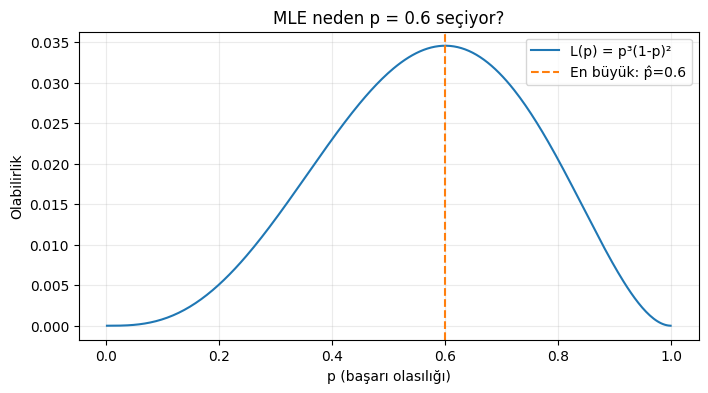

In [4]:
# Bernoulli MLE: hesaplama ve olabilirliğin p'ye bağlı grafiği
atiklar = np.array([1, 0, 1, 1, 0])
p_hat = atiklar.sum() / len(atiklar)
print("Başarı sayısı:", atiklar.sum())
print("Deneme sayısı:", len(atiklar))
print("MLE p̂ =", p_hat)

p_grid = np.linspace(0.001, 0.999, 300)
L = p_grid**3 * (1-p_grid)**2
plt.plot(p_grid, L, label="L(p) = p³(1-p)²")
plt.axvline(p_hat, color="tab:orange", linestyle="--", label=f"En büyük: p̂={p_hat:.1f}")
plt.xlabel("p (başarı olasılığı)")
plt.ylabel("Olabilirlik")
plt.title("MLE neden p = 0.6 seçiyor?")
plt.legend()
plt.show()

### Küçükten büyüğe örneklem etkisi
Gerçek para atışı başarı olasılığı $p=0.7$ olsun. 10, 50, 200 ve 1000 gözlemlik örneklemlerde $\hat p$ hesaplayalım. Her seferinde tam 0.7 çıkması beklenmez.

In [5]:
rng_bernoulli = np.random.default_rng(9)
gercek_p = 0.7
for n in [10, 50, 200, 1000]:
    orneklem = rng_bernoulli.binomial(1, gercek_p, size=n)
    print(f"N={n:4d}: başarı={orneklem.sum():4d}, p̂={orneklem.mean():.3f}")

N=  10: başarı=   4, p̂=0.400
N=  50: başarı=  30, p̂=0.600
N= 200: başarı= 137, p̂=0.685
N=1000: başarı= 707, p̂=0.707


### 4.2.2 Multinomial / kategorik dağılım

Bir deneyde $K$ sınıftan **tam biri** gerçekleşsin. $N_i$, $i$ sınıfındaki gözlem sayısı olsun:

$$\boxed{\hat p_i=\frac{N_i}{N}},\qquad \sum_i\hat p_i=1$$

**Sınıfa sor:** 20 üründen 10'u A, 6'sı B, 4'ü C ise sınıf olasılıkları ne?

**Eğitmene özel yanıt:** $0.50$, $0.30$, $0.20$. Toplam 1.

Sınıf A: 10/20 = 0.50
Sınıf B: 6/20 = 0.30
Sınıf C: 4/20 = 0.20


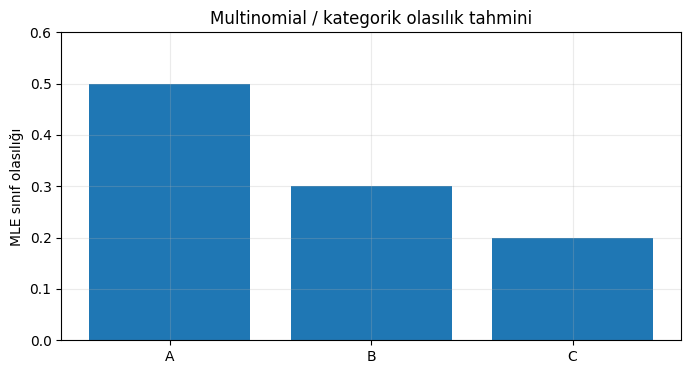

In [6]:
sayilar = np.array([10, 6, 4])
siniflar = ["A", "B", "C"]
olasiliklar = sayilar / sayilar.sum()
for isim, n, p in zip(siniflar, sayilar, olasiliklar):
    print(f"Sınıf {isim}: {n}/20 = {p:.2f}")

plt.bar(siniflar, olasiliklar)
plt.ylim(0, 0.6)
plt.ylabel("MLE sınıf olasılığı")
plt.title("Multinomial / kategorik olasılık tahmini")
plt.show()

---
# 3. Bölüm — Gaussian MLE, bias ve Bayesçi tahmin (25–40 dk)

### 4.2.3 Gaussian dağılım

$$X\sim\mathcal N(\mu,\sigma^2),\quad
p(x)=\frac{1}{\sqrt{2\pi}\sigma}\exp\left[-\frac{(x-\mu)^2}{2\sigma^2}\right]$$

- $\mu$: eğrinin merkezi (ortalama).
- $\sigma$: eğrinin genişliği (standart sapma).
- $\sigma^2$: varyans.

**MLE sonuçları:**

$$\boxed{m=\frac1N\sum_t x_t},\qquad \boxed{s^2=\frac1N\sum_t(x_t-m)^2}$$

**Uyarı:** Normal dağılım için **MLE varyansı $N$ ile böler**. Yansız örneklem varyansı $N-1$ ile böler. İki hedef aynı değildir.

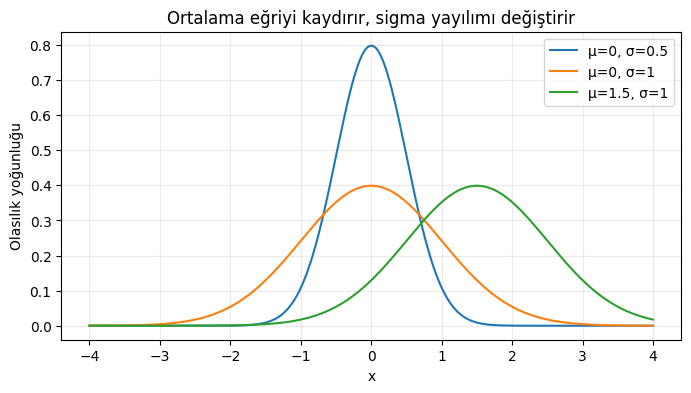

In [7]:
# Normal yoğunluk fonksiyonunu dış kütüphane olmadan yazalım.
def normal_pdf(x, mu, sigma):
    return np.exp(-0.5 * ((x-mu)/sigma)**2) / (np.sqrt(2*np.pi) * sigma)

xx = np.linspace(-4, 4, 500)
plt.plot(xx, normal_pdf(xx, 0, 0.5), label="μ=0, σ=0.5")
plt.plot(xx, normal_pdf(xx, 0, 1.0), label="μ=0, σ=1")
plt.plot(xx, normal_pdf(xx, 1.5, 1.0), label="μ=1.5, σ=1")
plt.xlabel("x")
plt.ylabel("Olasılık yoğunluğu")
plt.title("Ortalama eğriyi kaydırır, sigma yayılımı değiştirir")
plt.legend()
plt.show()

In [8]:
# Örneklem üzerinden N ve N-1 farkını görün.
puanlar = np.array([60., 70., 80.])
ortalama = puanlar.mean()
kare_toplami = np.sum((puanlar - ortalama)**2)
print("Ortalamamız:", ortalama)
print("Kareli sapma toplamı:", kare_toplami)
print("MLE varyans (N):", kare_toplami / len(puanlar))
print("Yansız varyans (N-1):", kare_toplami / (len(puanlar)-1))

Ortalamamız: 70.0
Kareli sapma toplamı: 200.0
MLE varyans (N): 66.66666666666667
Yansız varyans (N-1): 100.0


### 4.3 Bir tahmin edicide bias ve variance

Tahmin edici $d(X)$ için:

$$\operatorname{Bias}(d)=E[d(X)]-\theta$$
$$\boxed{\operatorname{MSE}(d)=\operatorname{Var}(d)+\operatorname{Bias}(d)^2}$$

**Yansızlık** tahminin her denemede doğru çıkması değildir; farklı örneklemler üzerinden ortalamasının doğru olmasıdır.

### 4.4 Bayesçi tahmin: önceki bilgi + yeni veri

Önsel: $\theta\sim\mathcal N(\mu_0,\sigma_0^2)$  
Gözlem modeli: $x_t\sim\mathcal N(\theta,\sigma^2)$ (gözlem varyansı biliniyor).

Sonsal ortalama (Bayes nokta tahmini):

$$\boxed{E[\theta\mid X]=\frac{(N/\sigma^2)m+(1/\sigma_0^2)\mu_0}{N/\sigma^2+1/\sigma_0^2}}$$

Yorum: İki ortalamanın **güvenilirliklerine göre ağırlıklı ortalaması**; veri sayısı büyüdükçe örneklem ortalaması daha fazla ağırlık alır.

**MAP:** Sonsal dağılımın en yüksek noktası. **MLE:** Verilerin olabilirliğinin en yüksek noktası. Bu örnekte sonsal normal olduğundan MAP = sonsal ortalama.

N= 1: MLE=9.0, Bayes=7.400
N= 4: MLE=9.0, Bayes=8.000
N=16: MLE=9.0, Bayes=8.600
N=64: MLE=9.0, Bayes=8.882


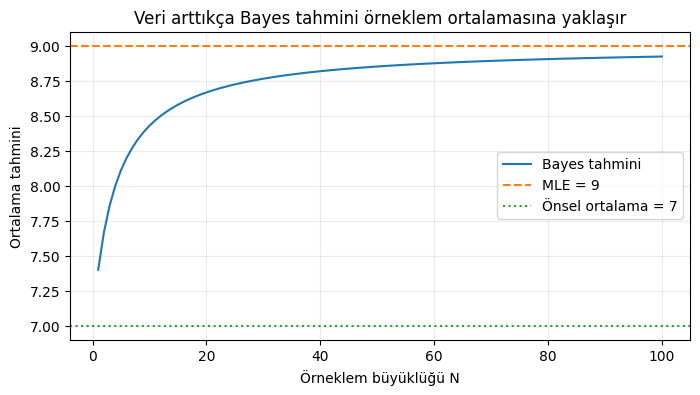

In [9]:
# Kitaptaki örneğe benzer: önsel ortalama 7, örneklem ortalaması 9.
mu0, prior_var = 7.0, 1.0
sigma2, m = 4.0, 9.0

def bayes_ortalama(n, m, sigma2, mu0, prior_var):
    veri_agirligi = n / sigma2
    onsel_agirlik = 1 / prior_var
    return (veri_agirligi*m + onsel_agirlik*mu0) / (veri_agirligi+onsel_agirlik)

for n in [1, 4, 16, 64]:
    print(f"N={n:2d}: MLE={m:.1f}, Bayes={bayes_ortalama(n,m,sigma2,mu0,prior_var):.3f}")

ns = np.arange(1, 101)
plt.plot(ns, [bayes_ortalama(n,m,sigma2,mu0,prior_var) for n in ns], label="Bayes tahmini")
plt.axhline(m, color="tab:orange", linestyle="--", label="MLE = 9")
plt.axhline(mu0, color="tab:green", linestyle=":", label="Önsel ortalama = 7")
plt.xlabel("Örneklem büyüklüğü N")
plt.ylabel("Ortalama tahmini")
plt.title("Veri arttıkça Bayes tahmini örneklem ortalamasına yaklaşır")
plt.legend()
plt.show()

> **Sınıfa sor:** Önsel bilgiye çok güveniyorsak önsel varyans $\sigma_0^2$ büyük mü, küçük mü olmalı?  
> **Eğitmene özel yanıt:** **Küçük** olmalı. Ağırlık $1/\sigma_0^2$ büyür.

---
# 4. Bölüm — Gaussian parametrik sınıflandırma (40–55 dk)

### 4.5 Parametrik sınıflandırma

Gözlemi sınıflara ait yoğunluklarla karşılaştıralım:

$$P(C_i\mid x)=\frac{p(x\mid C_i)P(C_i)}{\sum_k p(x\mid C_k)P(C_k)}$$

Ayırıcı fonksiyon:

$$g_i(x)=\log p(x\mid C_i)+\log P(C_i)$$

Sınıfa koşullu dağılım Gaussian varsayılırsa:

$$g_i(x)=-\frac12\log(2\pi)-\log\sigma_i-\frac{(x-\mu_i)^2}{2\sigma_i^2}+\log P(C_i)$$

Her sınıf için eğitim verisinden **ayrı ortalama, ayrı varyans ve önsel oran** tahmin ederiz.

**Özel durum:** Önsel olasılıklar ve varyanslar eşitse **en yakın ortalamalı sınıfı seçmek** yeterlidir. İki sınıf sınırı ortalamaların orta noktasıdır: $(\mu_1+\mu_2)/2$.

In [10]:
# Altı otomobil müşterisi: gelir ve satın alınan otomobil türü
# Gelir birimi bu örnekte temsili 'bin TL'dir.
c1 = np.array([20., 30., 40.])  # Ekonomik araç
c2 = np.array([60., 70., 80.])  # Lüks araç
X_gelir = np.r_[c1, c2]
y_sinif = np.array([0, 0, 0, 1, 1, 1])

m1, m2 = c1.mean(), c2.mean()
v1, v2 = np.mean((c1-m1)**2), np.mean((c2-m2)**2)
prior1, prior2 = len(c1)/len(X_gelir), len(c2)/len(X_gelir)

print("C1: ortalama", m1, "varyans", round(v1,2), "önsel", prior1)
print("C2: ortalama", m2, "varyans", round(v2,2), "önsel", prior2)
print("Eşit önsel / varyans karar sınırı:", (m1+m2)/2)

C1: ortalama 30.0 varyans 66.67 önsel 0.5
C2: ortalama 70.0 varyans 66.67 önsel 0.5
Eşit önsel / varyans karar sınırı: 50.0


Gelir=  35: P(C2|x)=0.000 -> Tahmin: C1 (ekonomik)
Gelir=  45: P(C2|x)=0.047 -> Tahmin: C1 (ekonomik)
Gelir=  50: P(C2|x)=0.500 -> Tahmin: eşit
Gelir=  65: P(C2|x)=1.000 -> Tahmin: C2 (lüks)


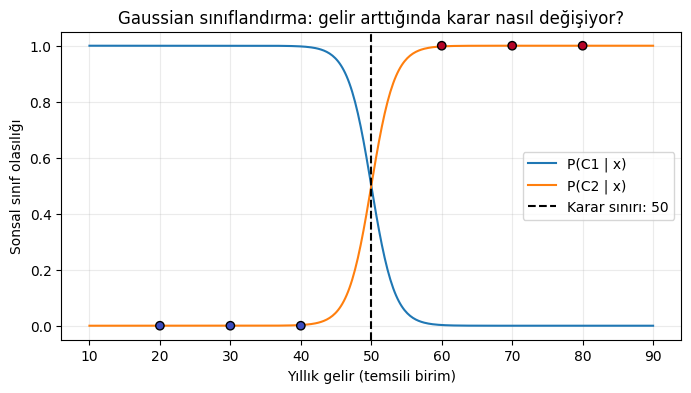

In [11]:
# Bayes kuralıyla sonsal olasılığı elle hesaplayalım.
def gaussian_posterior_c2(x, mu1, var1, prior1, mu2, var2, prior2):
    score1 = normal_pdf(x, mu1, np.sqrt(var1)) * prior1
    score2 = normal_pdf(x, mu2, np.sqrt(var2)) * prior2
    return score2 / (score1 + score2)

for gelir in [35., 45., 50., 65.]:
    p2 = gaussian_posterior_c2(gelir, m1,v1,prior1, m2,v2,prior2)
    print(f"Gelir={gelir:4.0f}: P(C2|x)={p2:.3f} -> Tahmin: {'C2 (lüks)' if p2>0.5 else 'C1 (ekonomik)' if p2<0.5 else 'eşit'}")

x_draw = np.linspace(10,90,400)
post2 = gaussian_posterior_c2(x_draw, m1,v1,prior1, m2,v2,prior2)
plt.plot(x_draw, 1-post2, label="P(C1 | x)")
plt.plot(x_draw, post2, label="P(C2 | x)")
plt.axvline(50, color="black", linestyle="--", label="Karar sınırı: 50")
plt.scatter(X_gelir, y_sinif, c=y_sinif, cmap="coolwarm", edgecolors="black", zorder=3)
plt.xlabel("Yıllık gelir (temsili birim)")
plt.ylabel("Sonsal sınıf olasılığı")
plt.title("Gaussian sınıflandırma: gelir arttığında karar nasıl değişiyor?")
plt.legend()
plt.show()

### Eşit olmayan varyans neden iki karar sınırı üretebilir?

Örnek: $C_1\sim\mathcal N(0,1)$ ve $C_2\sim\mathcal N(0,4)$, önseller eşit.

Merkezde dar dağılım ($C_1$) daha yoğunken, uçlarda geniş dağılım ($C_2$) baskın olabilir. Dolayısıyla **iki** kesişim noktası ortaya çıkabilir. (Her parametre seçiminde iki farklı gerçek kesişim olması zorunlu değildir.)

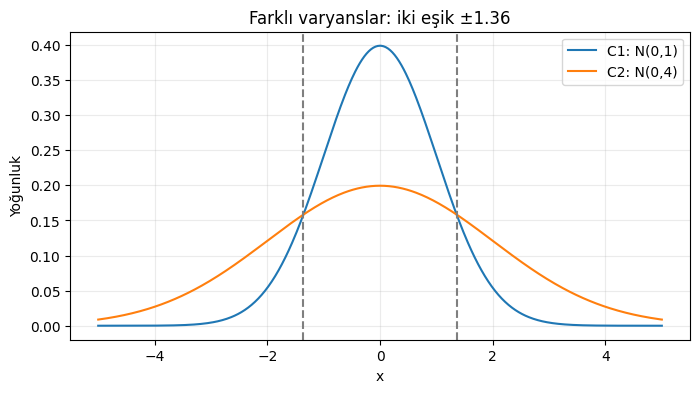

In [12]:
xs = np.linspace(-5, 5, 501)
d1 = normal_pdf(xs, 0, 1)
d2 = normal_pdf(xs, 0, 2)
boundary = np.sqrt(8*np.log(2)/3)
plt.plot(xs, d1, label="C1: N(0,1)")
plt.plot(xs, d2, label="C2: N(0,4)")
for signed in [-boundary,boundary]:
    plt.axvline(signed, linestyle="--", color="tab:gray")
plt.title(f"Farklı varyanslar: iki eşik ±{boundary:.2f}")
plt.xlabel("x")
plt.ylabel("Yoğunluk")
plt.legend()
plt.show()

**Sınıfa sor:** Önsel $P(C_1)$ artarsa karar sınırı ne tarafa kayar?  
**Eğitmene özel:** Eşit varyanslı iki ayrı merkez için, karar sınırı **daha az olası hâle gelen $C_2$ sınıfının ortalamasına doğru** kayar. Çünkü $C_2$ seçmek için daha güçlü veri kanıtı gerekir.

---
# 5. Bölüm — Regresyon ve en küçük kareler (55–80 dk)

### 4.6 Regresyon: Sayısal çıktı tahmini

Regresyonda $r=f(x)+\varepsilon$ kabul ederiz. Eğer hata $\varepsilon\sim\mathcal N(0,\sigma^2)$ ise:

$$r\mid x\sim\mathcal N(g(x\mid\theta),\sigma^2)$$

Log-olabilirliği maksimum yapmak, **kareli hata toplamını** minimum yapmakla aynı $\theta$ tahminini verir:

$$\boxed{E(\theta)=\frac12\sum_t [r^t-g(x_t\mid\theta)]^2}$$

**Kareli hata** neden kullanılır? Negatif ve pozitif farkların birbirini götürmesini engeller; büyük hataları daha çok cezalandırır.

**MSE**: $\frac1N\sum(r-\hat r)^2$; **SSE**: $\sum(r-\hat r)^2$.

### 4.6.1 Doğrusal regresyonu elle çözelim

Modelimiz: $\hat r=w_0+w_1x$.

Üç veri noktası: $(1,2)$, $(2,3)$, $(3,5)$.

Gerekli toplamlar: $N=3$, $\sum x=6$, $\sum r=10$, $\sum x^2=14$, $\sum xr=23$.

Normal denklemler:

$$\begin{cases}3w_0+6w_1=10\\6w_0+14w_1=23\end{cases}$$

İlkini ikiyle çarpıp ikinciden çıkarırsak: $2w_1=3\Rightarrow w_1=1.5$; ilk denkleme koyarsak $w_0=1/3$.

$$\boxed{\hat r=\frac13+1.5x}$$

In [13]:
# Yukarıdaki çözümü sayısal olarak aynı adımlarla kontrol edelim.
x_kucuk = np.array([1., 2., 3.])
r_kucuk = np.array([2., 3., 5.])
N = len(x_kucuk)

A = np.array([[N, x_kucuk.sum()],
              [x_kucuk.sum(), np.sum(x_kucuk**2)]])
y_vektor = np.array([r_kucuk.sum(), np.sum(x_kucuk * r_kucuk)])
w0, w1 = np.linalg.solve(A, y_vektor)

tahmin_kucuk = w0 + w1*x_kucuk
print("A matrisi:", A)
print("Sağ taraf y:", y_vektor)
print("w0 (sabit):", w0)
print("w1 (eğim):", w1)
print("Tahminler:", tahmin_kucuk)
print("SSE:", np.sum((r_kucuk-tahmin_kucuk)**2))
print("MSE:", np.mean((r_kucuk-tahmin_kucuk)**2))

A matrisi: [[ 3.  6.]
 [ 6. 14.]]
Sağ taraf y: [10. 23.]
w0 (sabit): 0.3333333333333333
w1 (eğim): 1.5
Tahminler: [1.833 3.333 4.833]
SSE: 0.16666666666666688
MSE: 0.05555555555555563


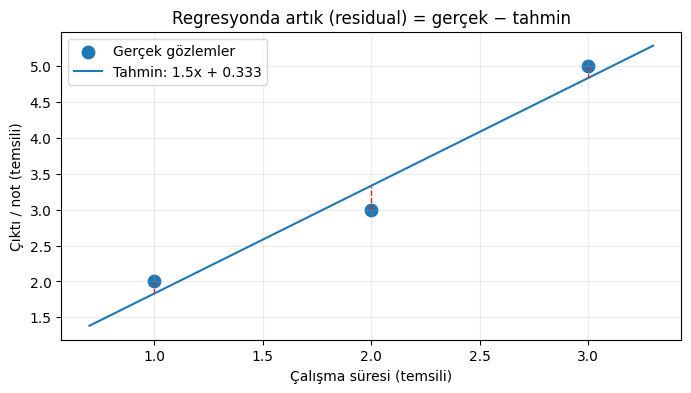

In [14]:
plt.scatter(x_kucuk, r_kucuk, s=80, label="Gerçek gözlemler")
x_line = np.linspace(0.7, 3.3, 100)
plt.plot(x_line, w0+w1*x_line, label=f"Tahmin: {w1:.1f}x + {w0:.3f}")
for x, r, r_hat in zip(x_kucuk,r_kucuk,tahmin_kucuk):
    plt.plot([x,x],[r,r_hat], linestyle="--", color="tab:red", linewidth=1)
plt.xlabel("Çalışma süresi (temsili)")
plt.ylabel("Çıktı / not (temsili)")
plt.title("Regresyonda artık (residual) = gerçek − tahmin")
plt.legend()
plt.show()

### 4.6.2 MSE, RSE ve $R^2$

**RSE (Relative Square Error):** Sabit olarak gerçek çıktı ortalamasını tahmin etmeye göre göreli hata.

$$\mathrm{RSE}=\frac{\sum_t(r^t-\hat r^t)^2}{\sum_t(r^t-\bar r)^2}$$

$$\boxed{R^2=1-\mathrm{RSE}}$$

- $R^2=1$: Kusursuz uyum.
- $R^2=0$: Çıktı ortalamasını tahmin etmekle aynı kareli hata.
- $R^2<0$: Referans ortalama tahmininden daha kötü (özellikle testte mümkündür).

In [15]:
sse = np.sum((r_kucuk - tahmin_kucuk)**2)
sst = np.sum((r_kucuk - r_kucuk.mean())**2)
rse = sse / sst
r_squared = 1 - rse
print("SSE =", round(sse, 6))
print("SST =", round(sst, 6))
print("RSE =", round(rse, 6))
print("R²  =", round(r_squared, 6))

SSE = 0.166667
SST = 4.666667
RSE = 0.035714
R²  = 0.964286


### 4.6.3 Polinom regresyonu: Daha esnek fonksiyonlar

Doğrusal: $g(x)=w_0+w_1x$  
İkinci derece: $g(x)=w_0+w_1x+w_2x^2$  
Genel: $g(x)=\sum_{j=0}^{k}w_jx^j$.

**Sık sorulan soru:** Polinom regresyonu neden hâlâ “parametrelerde doğrusal” modeldir?  
**Eğitmene özel:** $x^2,x^3$ gibi özellikler kullanılsa da bilinmeyen katsayılar $w_j$ sadece birinci kuvvettedir ve lineer biçimde toplanır.

Tasarım matrisi:

$$D=\begin{bmatrix}1&x_1&x_1^2&\cdots&x_1^k\\\vdots&\vdots&\vdots&&\vdots\\1&x_N&x_N^2&\cdots&x_N^k\end{bmatrix}$$

$$\boxed{w=(D^TD)^{-1}D^Tr}$$

Pratikte **matris tersini doğrudan hesaplamak yerine** sayısal olarak kararlı en küçük kareler yöntemini (`np.linalg.lstsq`, `np.polyfit`, QR/SVD) kullanırız.

Derece 1 katsayıları (en yüksek dereceden sabite): [ 4. -1.]
Derece 2 katsayıları (en yüksek dereceden sabite): [ 1. -0.  1.]
Derece 3 katsayıları (en yüksek dereceden sabite): [0. 1. 0. 1.]


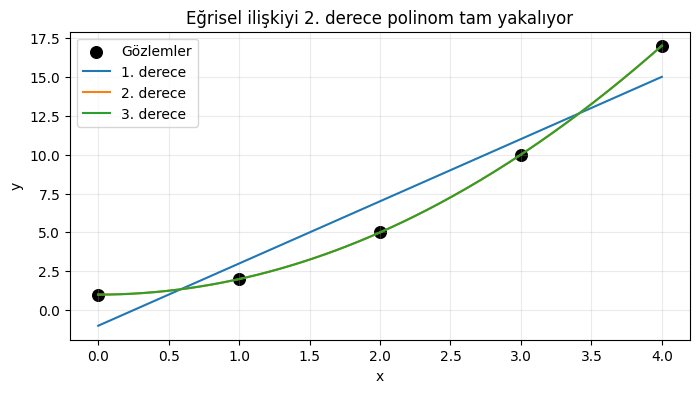

In [16]:
# 1, 2 ve 3. derece polinomun basit veri üzerindeki uyumunu karşılaştıralım.
x_poly = np.array([0., 1., 2., 3., 4.])
y_poly = np.array([1., 2., 5., 10., 17.])  # y = x^2 + 1
x_vis = np.linspace(0,4,200)

plt.scatter(x_poly, y_poly, s=70, color="black", label="Gözlemler")
for derece in [1,2,3]:
    katsayilar = np.polyfit(x_poly, y_poly, derece)
    tahmin = np.polyval(katsayilar, x_vis)
    print(f"Derece {derece} katsayıları (en yüksek dereceden sabite):", np.round(katsayilar, 3))
    plt.plot(x_vis, tahmin, label=f"{derece}. derece")
plt.xlabel("x")
plt.ylabel("y")
plt.title("Eğrisel ilişkiyi 2. derece polinom tam yakalıyor")
plt.legend()
plt.show()

> **Sınıfa sor:** Yukarıdaki örnekte neden 3. dereceden modelin ekstra katsayısı yaklaşık sıfır?  
> **Eğitmene özel:** Çünkü veriler tam olarak $y=x^2+1$ ilişkisine uyuyor; daha yüksek dereceye ihtiyaç yok. Gerçek gürültülü veride böyle net olmayabilir.

---
# 6. Bölüm — Bias / Variance ikilemi (80–95 dk)

### 4.7 Model karmaşıklığı neden tehlikeli olabilir?

Gerçek model $f(x)=2\sin(1.5x)$ olsun; gözlemlere sıfır ortalamalı Gaussian gürültü ekleyelim:

$$r=f(x)+\varepsilon,\qquad\varepsilon\sim\mathcal N(0,1)$$

Birçok farklı veri kümesi üretip **aynı polinom derecesini** her veri kümesinde yeniden eğiteceğiz.

Belirli bir $x$ noktasındaki beklenen kareli hata:

$$\boxed{\mathrm{MSE}(x)=\mathrm{Noise}(x)+\mathrm{Bias}^2(x)+\mathrm{Variance}(x)}$$

- **Bias:** Modellerin ortalama tahmini ile gerçek fonksiyon arasındaki sistematik fark.
- **Variance:** Farklı eğitim örneklemlerinin farklı tahminler üretmesi.
- **Noise:** Yalnızca girdi $x$ verildiğinde giderilemeyen rastgele değişkenlik.

**Düşük derece:** Genellikle yüksek bias / daha düşük variance (underfitting).  
**Yüksek derece:** Genellikle daha düşük bias / daha yüksek variance (overfitting riski).

Bu deney **simülasyondur**: Gerçek $f(x)$ fonksiyonunu bildiğimiz için bias hesabını yapabiliyoruz. Gerçek problemlerde bu fonksiyon genellikle bilinmez.

In [17]:
# Kitaptaki sinüs deneyinin tekrar edilebilir öğretici bir benzeri.
# Her derece için 60 BAĞIMSIZ eğitim veri kümesi oluşturuyoruz.
rng_sim = np.random.default_rng(2026)
def f_gercek(x):
    return 2*np.sin(1.5*x)

x_test_grid = np.linspace(0,5,140)
y_true_grid = f_gercek(x_test_grid)
M = 60       # Kaç farklı eğitim kümesi?
n_train = 24 # Her birinde kaç veri var?
dereceler = [1, 3, 5]

tahminler = {}
for derece in dereceler:
    tum_tahminler = []
    # Farklı dereceler için AYNI veri kümelerini yeniden üretmek için sabit tohum.
    local_rng = np.random.default_rng(2026)
    for tekrar in range(M):
        x = np.sort(local_rng.uniform(0,5,n_train))
        y = f_gercek(x) + local_rng.normal(0,1,n_train)
        katsayi = np.polyfit(x,y,derece)
        tum_tahminler.append(np.polyval(katsayi, x_test_grid))
    tahminler[derece] = np.array(tum_tahminler)

for derece in dereceler:
    g = tahminler[derece]
    ort_tahmin = g.mean(axis=0)
    bias2 = np.mean((ort_tahmin - y_true_grid)**2)
    varyans = np.mean(g.var(axis=0))
    beklenen_hata = bias2 + varyans + 1.0  # Gerçek gürültü varyansı 1
    print(f"Derece {derece}: bias²={bias2:6.3f}, variance={varyans:6.3f}, noise=1.000, toplam={beklenen_hata:6.3f}")

Derece 1: bias²= 1.646, variance= 0.208, noise=1.000, toplam= 2.855
Derece 3: bias²= 0.207, variance= 0.345, noise=1.000, toplam= 1.552
Derece 5: bias²= 0.023, variance= 0.750, noise=1.000, toplam= 1.774


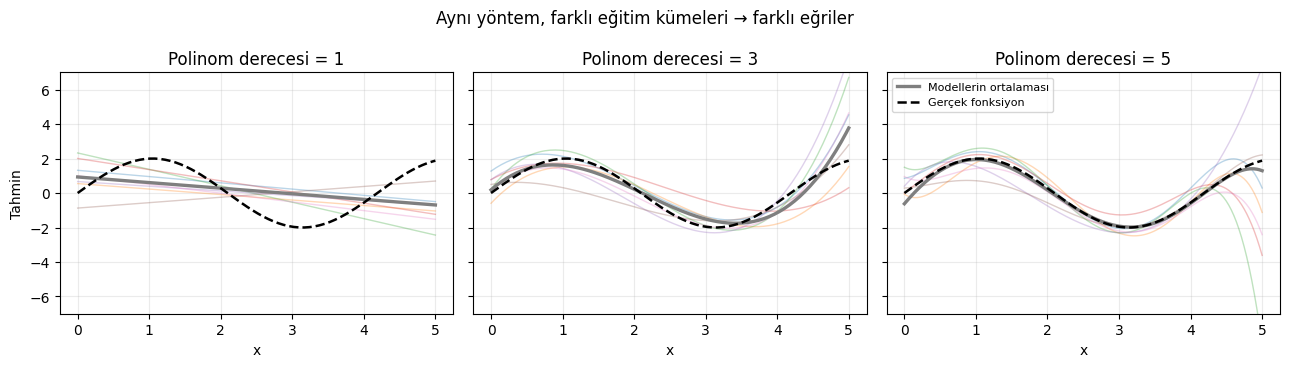

In [18]:
# Tek bir grafik: her karmaşıklık için birkaç model ve bunların ortalaması.
fig, axes = plt.subplots(1, 3, figsize=(13, 3.7), sharex=True, sharey=True)
for ax, derece in zip(axes, dereceler):
    arr = tahminler[derece]
    for i in range(7):
        ax.plot(x_test_grid, arr[i], alpha=0.3, linewidth=1)
    ax.plot(x_test_grid, arr.mean(axis=0), linewidth=2.4, label="Modellerin ortalaması")
    ax.plot(x_test_grid, y_true_grid, "k--", linewidth=1.8, label="Gerçek fonksiyon")
    ax.set_title(f"Polinom derecesi = {derece}")
    ax.set_xlabel("x")
    ax.set_ylim(-7, 7)
axes[0].set_ylabel("Tahmin")
axes[-1].legend(fontsize=8)
plt.suptitle("Aynı yöntem, farklı eğitim kümeleri → farklı eğriler")
plt.tight_layout()
plt.show()

### Grafik yorumu (öğrencilere açıklayın)

- **1. derece:** Eğriler birbirine görece yakın; gerçek sinüs şeklini yakalamak zor.
- **3. derece:** Daha iyi şekil uyumu, yönetilebilir esneklik.
- **5. derece:** Bazı denemelerde özellikle uçlarda daha belirgin dalgalanma.

**Ders sorusu:** Beşinci derece eğitim hatasında iyi olabilirken neden yeni veride kötüleşebilir?  
**Eğitmene özel:** Öğrenilmiş eğri, eğitim kümesindeki gürültüye daha fazla uyum sağlayabilir; varyans artar.

**Not:** Üçüncü derecenin her rastgele veri kümesinde en iyi çıkacağı garanti değildir; doğru model karmaşıklığı doğrulamayla seçilir.

---
# 7. Bölüm — Cross-validation ve regularization (95–110 dk)

### 4.8 Model seçimi: doğru uygulama sırası

1. **Test kümesini en başta ayır.** Testi hiperparametre seçiminde kullanma.
2. Geriye kalan eğitim tarafında adayları karşılaştırmak için **K-fold CV** uygula.
3. Doğrulama sonucuna göre **polinom derecesi** ve gerekiyorsa **$\lambda$** seç.
4. Seçilen modelle eğitim tarafındaki bütün veriyi kullanarak yeniden eğitim yap.
5. **En son** test hatasını raporla.

Önemli: Ön işleme (standartlaştırma, polinom özellikleri vb.) çapraz doğrulamanın her turunda **yalnızca o turun eğitim parçasına fit edilmeli**. `Pipeline` bu veri sızıntısını önler.

In [19]:
# Tek bir veri kümesi: eğitim/test bölünmesini SADECE BİR KEZ yapıyoruz.
rng_cv = np.random.default_rng(100)
x_all = rng_cv.uniform(0,5,180)
y_all = f_gercek(x_all) + rng_cv.normal(0,1,180)
X_all = x_all.reshape(-1,1)  # sklearn girdi boyutu (N, özellik_sayısı)

X_train, X_test, y_train, y_test = train_test_split(
    X_all, y_all, test_size=0.2, random_state=42
)
print("Toplam gözlem:", len(X_all))
print("Train tarafı:", len(X_train))
print("Dokunulmamış final test:", len(X_test))

Toplam gözlem: 180
Train tarafı: 144
Dokunulmamış final test: 36


### 7.1 5-Fold çapraz doğrulama ile polinom derecesi seçimi

Doğrulama sürecindeki beş parçanın her biri sırayla bir kez **validation**, geri kalanlar **training** olur.

Ölçüt MSE olduğu için `scikit-learn` içinde `'neg_mean_squared_error'` kullanılır: Puanlar **negatif** döner; karşılaştırmak için eksi işaretini kaldırırız.

Derece 1: CV MSE= 2.875 ±  0.473
Derece 2: CV MSE= 2.027 ±  0.261
Derece 3: CV MSE= 1.208 ±  0.479
Derece 4: CV MSE= 1.214 ±  0.359
Derece 5: CV MSE= 1.104 ±  0.358
Derece 6: CV MSE= 1.078 ±  0.332
Derece 7: CV MSE= 1.093 ±  0.327
Derece 8: CV MSE= 1.100 ±  0.318
CV ile seçilen derece: 6


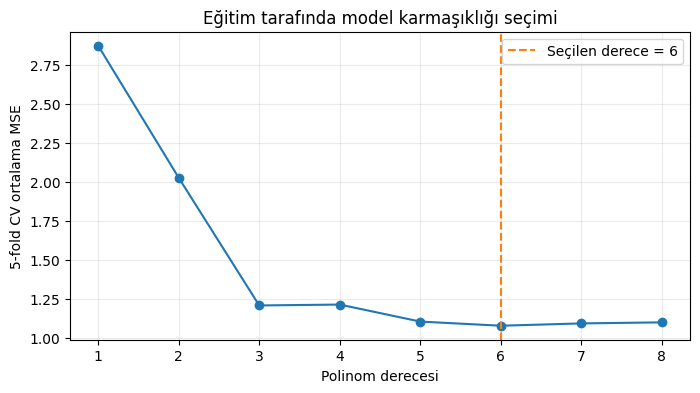

In [20]:
cv = KFold(n_splits=5, shuffle=True, random_state=42)
sonuclar = []
for derece in range(1,9):
    model = Pipeline([
        ("poly", PolynomialFeatures(degree=derece, include_bias=False)),
        ("scale", StandardScaler()),
        ("reg", LinearRegression())
    ])
    # score, negatif MSE olduğu için eksi alıp pozitif hataya çeviriyoruz.
    fold_mse = -cross_val_score(model, X_train, y_train,
                                cv=cv, scoring="neg_mean_squared_error")
    sonuclar.append((derece, fold_mse.mean(), fold_mse.std()))
    print(f"Derece {derece}: CV MSE={fold_mse.mean():6.3f} ± {fold_mse.std():6.3f}")

best_degree = min(sonuclar, key=lambda x: x[1])[0]
print("CV ile seçilen derece:", best_degree)

deg_arr = np.array([s[0] for s in sonuclar])
err_arr = np.array([s[1] for s in sonuclar])
plt.plot(deg_arr, err_arr, marker="o")
plt.axvline(best_degree, color="tab:orange", linestyle="--", label=f"Seçilen derece = {best_degree}")
plt.xlabel("Polinom derecesi")
plt.ylabel("5-fold CV ortalama MSE")
plt.title("Eğitim tarafında model karmaşıklığı seçimi")
plt.legend()
plt.show()

### 7.2 L2 düzenlileştirme (Ridge) ile karmaşıklığı kontrol etmek

Temel fikir:

$$\boxed{E=\sum_t(r_t-\hat r_t)^2+\lambda\sum_j w_j^2}$$

- $\lambda$ **küçük**: Ağırlıklara az ceza, daha esnek uyum.
- $\lambda$ **büyük**: Ağırlıklara daha fazla ceza, daha güçlü düzleştirme.
- $\lambda$ gereğinden fazla büyürse **underfitting** görülebilir.

Burada `Ridge(alpha=...)` kullanacağız; `alpha`, uygulama açısından regularization şiddetidir. Sabit terim Ridge tarafından varsayılan olarak cezalandırılmaz. Polinom özelliklerini standartlaştırmak önemlidir; yoksa büyük ölçekli özelliklerin ceza üzerindeki etkisi farklı olur.

In [21]:
# K-fold CV ile hem polinom derecesi hem regularization ağırlığı seçimi.
# Eğitim/test sızıntısını önlemek için tüm dönüşümler Pipeline içinde.
pipe = Pipeline([
    ("poly", PolynomialFeatures(include_bias=False)),
    ("scale", StandardScaler()),
    ("ridge", Ridge())
])

grid = {
    "poly__degree": [1, 2, 3, 4, 5, 6, 7],
    "ridge__alpha": [0.01, 0.1, 1.0, 10.0]
}

arama = GridSearchCV(
    pipe,
    param_grid=grid,
    scoring="neg_mean_squared_error",
    cv=cv,
    n_jobs=1,
    refit=True
)
arama.fit(X_train, y_train)

print("Seçilen hiperparametreler:", arama.best_params_)
print("En iyi CV MSE:", round(-arama.best_score_, 4))

# TEST'e ilk ve tek bakış; bu sonucu hiperparametre seçmekte kullanmayacağız.
y_hat_test = arama.predict(X_test)
print("Final test MSE:", round(mean_squared_error(y_test, y_hat_test), 4))
print("Final test R²:", round(r2_score(y_test, y_hat_test), 4))

Seçilen hiperparametreler: {'poly__degree': 7, 'ridge__alpha': 0.01}
En iyi CV MSE: 1.1327
Final test MSE: 0.8098
Final test R²: 0.7115


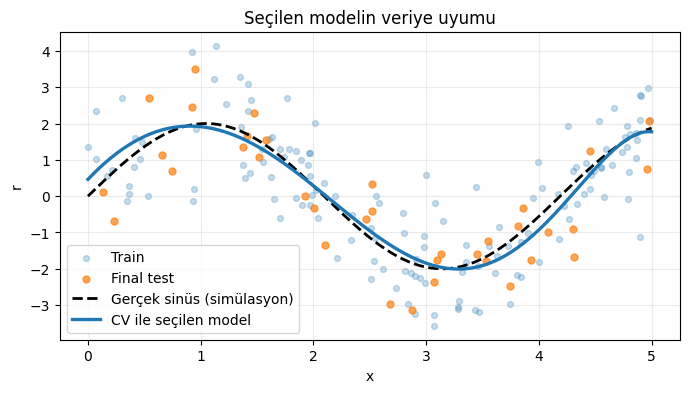

In [22]:
# Son modelin daha önce görmediği test verileriyle karşılaştırılması.
x_axis = np.linspace(0,5,300).reshape(-1,1)
plt.scatter(X_train[:,0], y_train, alpha=.25, s=18, label="Train", color="tab:blue")
plt.scatter(X_test[:,0], y_test, alpha=.7, s=25, label="Final test", color="tab:orange")
plt.plot(x_axis[:,0], f_gercek(x_axis[:,0]), "k--", linewidth=2, label="Gerçek sinüs (simülasyon)")
plt.plot(x_axis[:,0], arama.predict(x_axis), linewidth=2.4, label="CV ile seçilen model")
plt.xlabel("x")
plt.ylabel("r")
plt.title("Seçilen modelin veriye uyumu")
plt.legend()
plt.show()

**Eğitmene özel uyarı:** Yukarıdaki test sonucunu gördükten sonra `GridSearchCV` ayarlarını test hatasını düşürmek için tekrar tekrar değiştirmek doğru değildir; bu, test kümesine dolaylı uyum yaratır. Eğer bir yöntem karşılaştırması daha yapılacaksa iç doğrulama veya iç içe çapraz doğrulama gerekir.

**Sınıfa sor:** `StandardScaler` adımını neden `train_test_split` öncesinde bütün veriye `fit` etmedik?  
**Eğitmene özel:** Test setinin ortalaması ve varyansı eğitim sürecine sızardı. Pipeline bunu her CV turunda da engeller.

---
# 8. Bölüm — AIC, BIC, SRM, MDL ve hızlı tekrar (110–120 dk)

### 4.8 Model seçimine başka bakışlar

| Yaklaşım | Temel fikir |
|---|---|
| **AIC** | Uyum ile parametre sayısını dengele ($2k-2\log\hat L$) |
| **BIC** | Uyum ile örneklem büyüklüğüne bağlı karmaşıklığı dengele ($k\log N-2\log\hat L$) |
| **SRM** | Artan karmaşıklıkta hipotez sınıfları için genelleme riski/karmaşıklık dengesini gözet |
| **MDL** | Veriyi açıklayan model + geriye kalan verinin en kısa toplam tanımını seç |
| **Bayesçi model seçimi** | $p(M\mid D)\propto p(D\mid M)p(M)$ ile önsel bilgiyi ve veri kanıtını birleştir |

**Önemli:** Hepsi aynı yöntem değildir; ortak amaçları iyi uyum ile gereksiz karmaşıklığı dengelemektir.

### AIC/BIC mini örneği

Aşağıdaki uygulama eğitim verisi üzerinde Gaussian hata varsayımı altında hesaplanan **karşılaştırmalı** bilgi kriterlerini gösterir. Gaussian log-likelihood'daki bütün adaylara ortak sabiti atıyoruz; bu nedenle elde edilen sayılar modeller arası sıralama amaçlıdır. $k$ içinde polinom katsayıları ve bilinmeyen gürültü varyansı bulunmaktadır.

In [23]:
# AIC ve BIC'yi dereceli polinomlar için karşılaştıralım.
# Eğitim verisini kullanıyoruz; test kümesine dokunmuyoruz.
n = len(X_train)
print("Derece | AIC (sabit hariç) | BIC (sabit hariç)")
print("-"*47)
for derece in range(1, 7):
    model = Pipeline([
        ("poly", PolynomialFeatures(degree=derece, include_bias=False)),
        ("lin", LinearRegression())
    ])
    model.fit(X_train, y_train)
    y_hat = model.predict(X_train)
    sse = np.sum((y_train-y_hat)**2)
    param_count = (derece + 1) + 1  # intercept+katsayılar+gürültü varyansı
    aic = n*np.log(sse/n) + 2*param_count
    bic = n*np.log(sse/n) + np.log(n)*param_count
    print(f"{derece:6d} | {aic:17.3f} | {bic:17.3f}")

Derece | AIC (sabit hariç) | BIC (sabit hariç)
-----------------------------------------------
     1 |           155.392 |           164.301
     2 |           104.867 |           116.747
     3 |            28.689 |            43.538
     4 |            19.550 |            37.369
     5 |             5.579 |            26.368
     6 |             3.308 |            27.067


### 4.9 Kısa not: Sınıflandırma ve regresyon kaybı aynı değildir

Regresyonda kareli hata değişimin büyüklüğünü sürekli olarak ölçer. Sınıflandırmada **0/1 loss**, yalnızca kararın doğru ya da yanlış olduğuna bakar. $P(C_1\mid x)=0.7$ iken 0.8 tahminiyle 0.6 tahmini, 0.5 eşiğinde aynı sınıfı seçer; fakat olasılık kalibrasyonları aynı değildir. Bu nedenle regresyondaki basit $\mathrm{Bias}^2+\mathrm{Variance}+\mathrm{Noise}$ ayrışımını 0/1 sınıflandırma kaybına doğrudan uygulamıyoruz.

### Çıkış bileti — 5 kısa soru (3–4 dk)

1. Bernoulli dağılımında 20 denemeden 15'i başarıysa MLE $\hat p$ kaçtır?
2. Sınıf önselleri ve varyanslar eşitse Gaussian sınıflandırmada karar sınırı nasıl bulunur?
3. Normal dağılımlı sabit varyanslı hata altında MLE regresyon hangi hatayı azaltır?
4. Eğitim MSE'si azalırken doğrulama MSE'sinin yükselmesi neye işaret eder?
5. Hiperparametre seçerken test verisi mi, cross-validation mı kullanılmalıdır?

#### Eğitmene özel yanıt anahtarı

1. $15/20=0.75$.
2. İki sınıf ortalamasının orta noktası: $(\mu_1+\mu_2)/2$.
3. Kareli hata toplamı (SSE); MSE ile aynı minimizer.
4. Overfitting/aşırı karmaşıklık olasılığına.
5. Eğitim tarafındaki cross-validation; **test** yalnızca nihai değerlendirmede kullanılır.

## Öğretmen için kapanış konuşması (son 1–2 dakika)

Bugün tek bir ana fikri farklı yerlerde kullandık: **Veriden tahmin ettiğimiz parametrelerle kurduğumuz model yeni veride de çalışmalı.**

- MLE bize veriyle en uyumlu parametreyi bulmayı öğretti.
- Bayesçi yaklaşım bu parametreye önceki bilgiyi ekledi.
- Regresyonda Gaussian hata varsayımı en küçük karelere bağlandı.
- Bias/variance, çok basit ve çok karmaşık modellerin farklı türde hata ürettiğini gösterdi.
- Cross-validation ve regularization ile model seçimini yalnızca eğitim hatasına bırakmamayı öğrendik.

**Dönem projesi bağlantısı:** Veri kümesi seç → train/validation/test ayır → en az 3 modeli karşılaştır → CV ile ayarla → testte bir kez değerlendir. Sınıflandırmada accuracy/precision/recall/F1, regresyonda MSE/RMSE/MAE/$R^2$ seçimi problemi belirler.

### Kaynak ve kapsam

Ana bölüm sırası ve kavramlar: Alpaydın (2014), *Introduction to Machine Learning*, Bölüm 4, §4.1–4.10. Grafik ve sayısal simülasyonlar öğretim amaçlı **yeniden üretilmiştir**; kitaptaki özgün grafiklerin sayısal kopyası değildir. AIC/BIC ve scikit-learn kodları ders için eklenmiş uygulamalardır.

---
# Ders sonrası / zaman kalırsa (120 dakikaya dahil değil)

### 4.10 Alıştırmalarına yönelik uygulama ödevleri

1. Bernoulli için gerçek $p=0.2$, $0.5$, $0.8$ seçip $N=10,100,1000$ büyüklüklerinde MLE tahminlerini karşılaştırın.
2. Multinomial sınıf sayısı üçten beşe çıkarıldığında olasılıkların toplamının neden 1 kaldığını gösterin.
3. Gaussian dağılımda $N$ ve $N-1$ ile hesaplanan varyansları farklı örneklem büyüklüklerinde karşılaştırın.
4. Gaussian sınıflandırmada $P(C_1)=0.8$, $P(C_2)=0.2$ yapıp karar sınırının değişimini gözlemleyin.
5. Polinom derecelerini 1–10 değiştirerek eğitim ve doğrulama hatası eğrilerini inceleyin.
6. $\lambda$ değerini $10^{-4}$–$10^3$ aralığında tarayarak Ridge'nin etkisini tartışın.
7. Eğitim kümesini küçültün (ör. 144 yerine 30). CV ve seçilen hiperparametreler nasıl değişti?
8. Regresyon hedefi yerine iki sınıflı veri seçerek doğruluk ve F1 ölçütlerini karşılaştırın.

> **Eğitmen notu:** Buradaki uygulamalar ders süresindeki anlatımdan sonra kişisel çalışma veya lab ödevi olarak verilebilir. §4.10'un bütün teorik alıştırmaları bu 120 dakikalık akışa sıkıştırılmamıştır.